# 04 · EMT-TF Expression — Wu et al. 2020 AML  (unconditional, final notebook)

The EMT-transcription-factor expression step is unconditional and always the **last** notebook; with
Gate 2 NO-GO it is renumbered to **04** (spec sec6). We overlay, on the grey manifold, cells that
**detectably express** each candidate EMT-TF, using the reference's **categorical thresholded-expresser**
style (not a continuous single-gene colormap; per 04_test Sun rule). The candidate panel is widened
beyond Snail/Zeb/Twist to include the **FOXC and PRRX** mesenchymal families (Kürten lesson); VIM is
**excluded** (mesenchymal marker, not a TF). Factors are gated on detectable expression. Deliverable: `expression.pdf`.

In [ ]:
import os, sys, warnings
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_out = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad')); print(adata.shape)
# candidate EMT-TF panel (VIM excluded: not a TF)
panel = ['SNAI1','SNAI2','SNAI3','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
det = {}
for g in present:
    x = adata[:, g].X; x = np.asarray(x.todense()).ravel() if hasattr(x,'todense') else np.asarray(x).ravel()
    det[g] = 100*(x>0).mean()
det = pd.Series(det).sort_values(ascending=False)
print('candidate panel detection (% cells expressing):')
print(det.round(2).to_string())
DET_FLOOR = 3.0
keep = det[det >= DET_FLOOR].index.tolist()
print(f'\ncleared >= {DET_FLOOR}% floor:', keep, '(myeloid blasts barely express epithelial EMT-TFs)')

(96413, 13907)
candidate panel detection (% cells expressing):
ZEB2      5.12
SNAI3     0.91
ZEB1      0.50
TWIST2    0.02
SNAI1     0.01

cleared >= 3.0% floor: ['ZEB2'] (myeloid blasts barely express epithelial EMT-TFs)


In [ ]:
# choose the two best-detected factors for the categorical overlay; set per-gene thresholds at
# each factor's ~90th percentile among expressers so the overlay marks the clear high-expressers
show = keep[:2] if len(keep) >= 2 else keep
colors = ['tab:blue','tab:red','tab:green']
g_plt = {}
for g, c in zip(show, colors):
    x = adata[:, g].X; x = np.asarray(x.todense()).ravel() if hasattr(x,'todense') else np.asarray(x).ravel()
    pos = x[x>0]; thr = float(np.quantile(pos, 0.75)) if pos.size else 0.0
    g_plt[g] = (c, thr)
print('overlay factors + thresholds:', {k:(v[0],round(v[1],2)) for k,v in g_plt.items()})

overlay factors + thresholds: {'ZEB2': ('tab:blue', 0.79)}


wrote expression.pdf; factors shown: ['ZEB2']


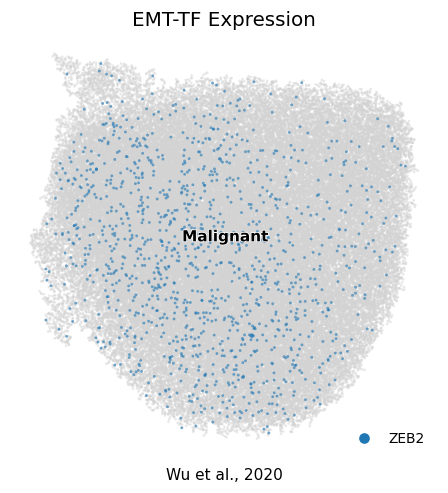

In [ ]:
# expression.pdf -- reference categorical thresholded-expresser overlay on grey manifold
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=12, alpha=.5, frameon=False, show=False, ax=ax)
for var, (c, thr) in g_plt.items():
    sub = adata[np.asarray((adata[:, var].X > thr).todense()).ravel()].copy() if hasattr(adata[:,var].X,'todense') \
          else adata[np.asarray(adata[:, var].X > thr).ravel()].copy()
    sc.pl.umap(sub, na_color=c, size=14, alpha=.6, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=12, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=c,markersize=8,label=v)
                   for v,(c,_) in g_plt.items()], loc='lower right', frameon=False, fontsize=9)
ax.set_title('EMT-TF Expression', size=13)
ax.text(.5, -.05, 'Wu et al., 2020', ha='center', transform=ax.transAxes)
plt.savefig(os.path.join(pth_out, 'expression.pdf'), bbox_inches='tight'); plt.show()
print('wrote expression.pdf; factors shown:', list(g_plt))

**EMT-TF readout.** In AML blasts the canonical epithelial EMT-TF programme is essentially silent —
Snail/Twist/FOXC/PRRX families are undetectable. Only **ZEB2** (and marginally SNAI1/ZEB1) clears the
3% detection floor, with no spatial polarity on the manifold. This is expected for a myeloid malignancy
and is consistent with the Gate-2 NO-GO: there is no embryonic EMT axis for these factors to mark.